<a href="https://colab.research.google.com/github/haniyathul/TESIS-HANIY/blob/main/Data_Oseanografi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip -q install xarray netCDF4 folium branca matplotlib

import xarray as xr
import pandas as pd
import numpy as np
from google.colab import files

# Upload semua file NetCDF bulanan
uploaded = files.upload()

# Buka file dan kumpulkan variabel
data_nc = {}
ringkasan = []

for nama_file in uploaded:
    if not nama_file.endswith(".nc"):
        continue

    ds = xr.open_dataset(nama_file)

    print("\nFILE:", nama_file)
    print("Variabel:", list(ds.data_vars))
    print("Dimensi:", dict(ds.sizes))
    print("Waktu:", ds.time.values)

    for var in ds.data_vars:
        if var in data_nc:
            print("PERINGATAN: variabel duplikat:", var)

        data_nc[var] = ds[var]

        ringkasan.append({
            "Variabel": var,
            "Satuan": ds[var].attrs.get("units", "-"),
            "Ukuran data": str(ds[var].shape),
            "File": nama_file
        })

# Tampilkan ringkasan semua variabel
tabel_variabel = pd.DataFrame(ringkasan)
display(tabel_variabel)

print("\nTotal variabel:", len(data_nc))
print("Daftar:", list(data_nc.keys()))



Saving cmems_mod_glo_bgc-bio_anfc_0.25deg_P1M-m_1794882863900.nc to cmems_mod_glo_bgc-bio_anfc_0.25deg_P1M-m_1794882863900.nc
Saving cmems_mod_glo_bgc-pft_anfc_0.25deg_P1M-m_1794882935592.nc to cmems_mod_glo_bgc-pft_anfc_0.25deg_P1M-m_1794882935592.nc
Saving cmems_mod_glo_phy_anfc_0.083deg_P1M-m_1794882226156.nc to cmems_mod_glo_phy_anfc_0.083deg_P1M-m_1794882226156.nc
Saving cmems_mod_glo_phy-cur_anfc_0.083deg_P1M-m_1794882530643.nc to cmems_mod_glo_phy-cur_anfc_0.083deg_P1M-m_1794882530643.nc
Saving cmems_mod_glo_phy-so_anfc_0.083deg_P1M-m_1794882485060.nc to cmems_mod_glo_phy-so_anfc_0.083deg_P1M-m_1794882485060.nc
Saving cmems_mod_glo_phy-thetao_anfc_0.083deg_P1M-m_1794882420845.nc to cmems_mod_glo_phy-thetao_anfc_0.083deg_P1M-m_1794882420845.nc

FILE: cmems_mod_glo_bgc-bio_anfc_0.25deg_P1M-m_1794882863900.nc
Variabel: ['nppv', 'o2']
Dimensi: {'time': 2, 'depth': 1, 'latitude': 61, 'longitude': 97}
Waktu: ['2026-09-01T00:00:00.000000000' '2026-10-01T00:00:00.000000000']

FILE: cmem

,Variabel,Satuan,Ukuran data,File
0,nppv,mg m-3 day-1,"(2, 1, 61, 97)",cmems_mod_glo_bgc-bio_anfc_0.25deg_P1M-m_17948...
1,o2,mmol m-3,"(2, 1, 61, 97)",cmems_mod_glo_bgc-bio_anfc_0.25deg_P1M-m_17948...
2,chl,mg m-3,"(2, 1, 61, 97)",cmems_mod_glo_bgc-pft_anfc_0.25deg_P1M-m_17948...
3,zos,m,"(2, 181, 288)",cmems_mod_glo_phy_anfc_0.083deg_P1M-m_17948822...
4,mlotst,m,"(2, 181, 288)",cmems_mod_glo_phy_anfc_0.083deg_P1M-m_17948822...
5,uo,m s-1,"(2, 1, 181, 288)",cmems_mod_glo_phy-cur_anfc_0.083deg_P1M-m_1794...
6,vo,m s-1,"(2, 1, 181, 288)",cmems_mod_glo_phy-cur_anfc_0.083deg_P1M-m_1794...
7,so,1e-3,"(2, 1, 181, 288)",cmems_mod_glo_phy-so_anfc_0.083deg_P1M-m_17948...
8,thetao,degrees_C,"(2, 1, 181, 288)",cmems_mod_glo_phy-thetao_anfc_0.083deg_P1M-m_1...



Total variabel: 9
Daftar: ['nppv', 'o2', 'chl', 'zos', 'mlotst', 'uo', 'vo', 'so', 'thetao']


Jumlah sel laut: 40213


,latitude,longitude,time,depth,thetao
0,-10.0,112.000015,2026-09-01,0.494025,26.681471
1,-10.0,112.083351,2026-09-01,0.494025,26.694918
2,-10.0,112.166679,2026-09-01,0.494025,26.707724
3,-10.0,112.250015,2026-09-01,0.494025,26.715757
4,-10.0,112.333351,2026-09-01,0.494025,26.723803
5,-10.0,112.416679,2026-09-01,0.494025,26.728928
6,-10.0,112.500015,2026-09-01,0.494025,26.737598
7,-10.0,112.583351,2026-09-01,0.494025,26.748642
8,-10.0,112.666687,2026-09-01,0.494025,26.760803
9,-10.0,112.750015,2026-09-01,0.494025,26.773983


,thetao
count,40213.000000
mean,28.095112
std,1.471837
min,23.813427
25%,26.824945
50%,27.779057
75%,29.414392
max,32.342037


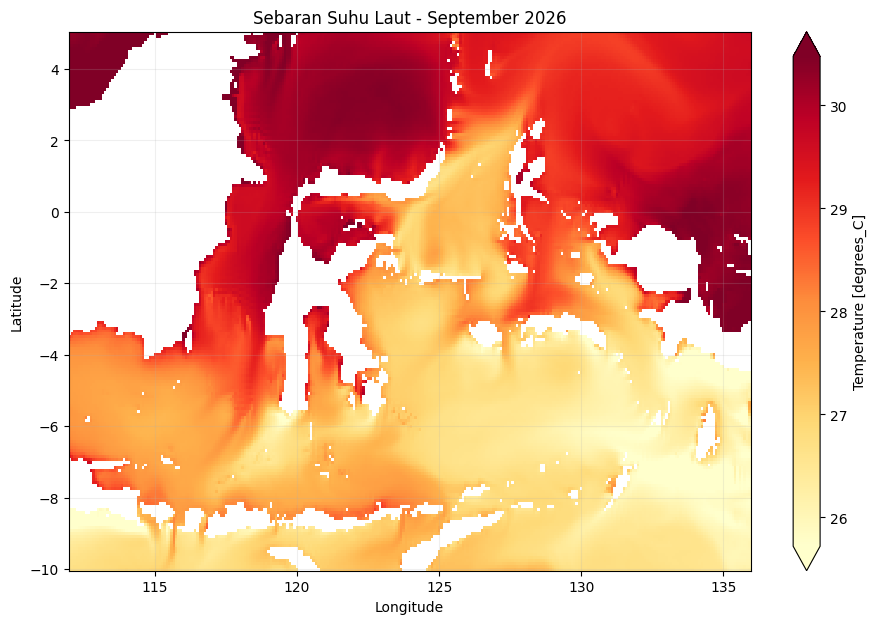

In [2]:

import matplotlib.pyplot as plt

# Pilih variabel dan bulan
variabel = "thetao"
bulan = "2026-09-01"

da = data_nc[variabel].sel(time=bulan, method="nearest")

# Gunakan kedalaman permukaan
if "depth" in da.dims:
    da = da.isel(depth=0)

# Lihat data dalam bentuk tabel
tabel = da.to_dataframe(name=variabel).reset_index()
tabel = tabel.dropna(subset=[variabel])

print("Jumlah sel laut:", len(tabel))
display(tabel.head(15))

# Statistik deskriptif
display(tabel[variabel].describe().to_frame())

# Peta spasial sederhana
plt.figure(figsize=(11, 7))

da.plot(
    x="longitude",
    y="latitude",
    cmap="YlOrRd",
    robust=True
)

plt.title("Sebaran Suhu Laut - September 2026")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.2)
plt.show()


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Variabel yang ingin ditampilkan
daftar_variabel = ["thetao", "so", "uo", "vo", "zos", "mlotst", "o2", "chl", "nppv"]

# Variabel yang sering lebih enak dilihat dalam skala log
log_vars = {"chl", "nppv"}

def ambil_2d(data_nc, variabel, waktu):
    """
    Ambil data 2D (lat-lon) untuk satu variabel dan satu waktu.
    Jika ada dimensi depth, ambil depth pertama / permukaan.
    """
    da = data_nc[variabel].sel(time=waktu, method="nearest")

    if "depth" in da.dims:
        da = da.isel(depth=0)

    return da.squeeze()

def info_variabel(data_nc):
    rows = []
    for var in data_nc:
        da = data_nc[var]
        rows.append({
            "variabel": var,
            "dims": da.dims,
            "shape": da.shape,
            "units": da.attrs.get("units", "-"),
            "time": list(pd.to_datetime(da.time.values).strftime("%Y-%m-%d"))
        })
    return pd.DataFrame(rows)

In [5]:
display(info_variabel(data_nc))

,variabel,dims,shape,units,time
0,nppv,"(time, depth, latitude, longitude)","(2, 1, 61, 97)",mg m-3 day-1,"[2026-09-01, 2026-10-01]"
1,o2,"(time, depth, latitude, longitude)","(2, 1, 61, 97)",mmol m-3,"[2026-09-01, 2026-10-01]"
2,chl,"(time, depth, latitude, longitude)","(2, 1, 61, 97)",mg m-3,"[2026-09-01, 2026-10-01]"
3,zos,"(time, latitude, longitude)","(2, 181, 288)",m,"[2026-09-01, 2026-10-01]"
4,mlotst,"(time, latitude, longitude)","(2, 181, 288)",m,"[2026-09-01, 2026-10-01]"
5,uo,"(time, depth, latitude, longitude)","(2, 1, 181, 288)",m s-1,"[2026-09-01, 2026-10-01]"
6,vo,"(time, depth, latitude, longitude)","(2, 1, 181, 288)",m s-1,"[2026-09-01, 2026-10-01]"
7,so,"(time, depth, latitude, longitude)","(2, 1, 181, 288)",1e-3,"[2026-09-01, 2026-10-01]"
8,thetao,"(time, depth, latitude, longitude)","(2, 1, 181, 288)",degrees_C,"[2026-09-01, 2026-10-01]"


In [10]:
def plot_semua_variabel_per_bulan(data_nc, waktu, figsize=(18, 14)):
    fig, axes = plt.subplots(3, 3, figsize=figsize)
    axes = axes.ravel()

    for i, var in enumerate(daftar_variabel):
        ax = axes[i]
        da = ambil_2d(data_nc, var, waktu)

        # Untuk chl dan nppv, pakai log1p agar pola lebih kelihatan
        if var in log_vars:
            plot_da = np.log1p(da)
            judul = f"{var} (log1p)"
            cbar_label = f"log1p({da.attrs.get('units', '-')})"
        else:
            plot_da = da
            judul = var
            cbar_label = da.attrs.get("units", "-")

        p = plot_da.plot(
            ax=ax,
            x="longitude",
            y="latitude",
            cmap="YlOrRd",
            robust=True,
            add_colorbar=False
        )

        cbar = fig.colorbar(p, ax=ax, shrink=0.8)
        cbar.set_label(cbar_label, fontsize=8)

        ax.set_title(judul, fontsize=11)
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
        ax.grid(alpha=0.2)

    plt.suptitle(f"Visualisasi 9 Variabel Oseanografi - {pd.to_datetime(waktu).strftime('%B %Y')}", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

In [11]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

daftar_variabel = [
    "thetao", "so", "uo", "vo",
    "zos", "mlotst", "o2", "chl", "nppv"
]

# Membuat satu data spasial untuk seluruh periode
data_periode = {}

for var in daftar_variabel:
    da = data_nc[var]

    # Pilih September dan Oktober 2026
    da = da.sel(time=slice("2026-09-01", "2026-10-31"))

    # Ambil lapisan permukaan jika ada dimensi depth
    if "depth" in da.dims:
        da = da.isel(depth=0)

    # Rata-rata September–Oktober per lokasi
    rata_rata = da.mean(dim="time", skipna=True)

    data_periode[var] = rata_rata

    print(
        var,
        "| Ukuran:", rata_rata.shape,
        "| Rata-rata:", round(float(rata_rata.mean()), 3)
    )

print("\nSelesai: 9 variabel untuk satu periode pengamatan.")


thetao | Ukuran: (181, 288) | Rata-rata: 28.529
so | Ukuran: (181, 288) | Rata-rata: 34.286
uo | Ukuran: (181, 288) | Rata-rata: -0.067
vo | Ukuran: (181, 288) | Rata-rata: -0.036
zos | Ukuran: (181, 288) | Rata-rata: 0.491
mlotst | Ukuran: (181, 288) | Rata-rata: 15.438
o2 | Ukuran: (61, 97) | Rata-rata: 204.829
chl | Ukuran: (61, 97) | Rata-rata: 0.215
nppv | Ukuran: (61, 97) | Rata-rata: 10.35

Selesai: 9 variabel untuk satu periode pengamatan.


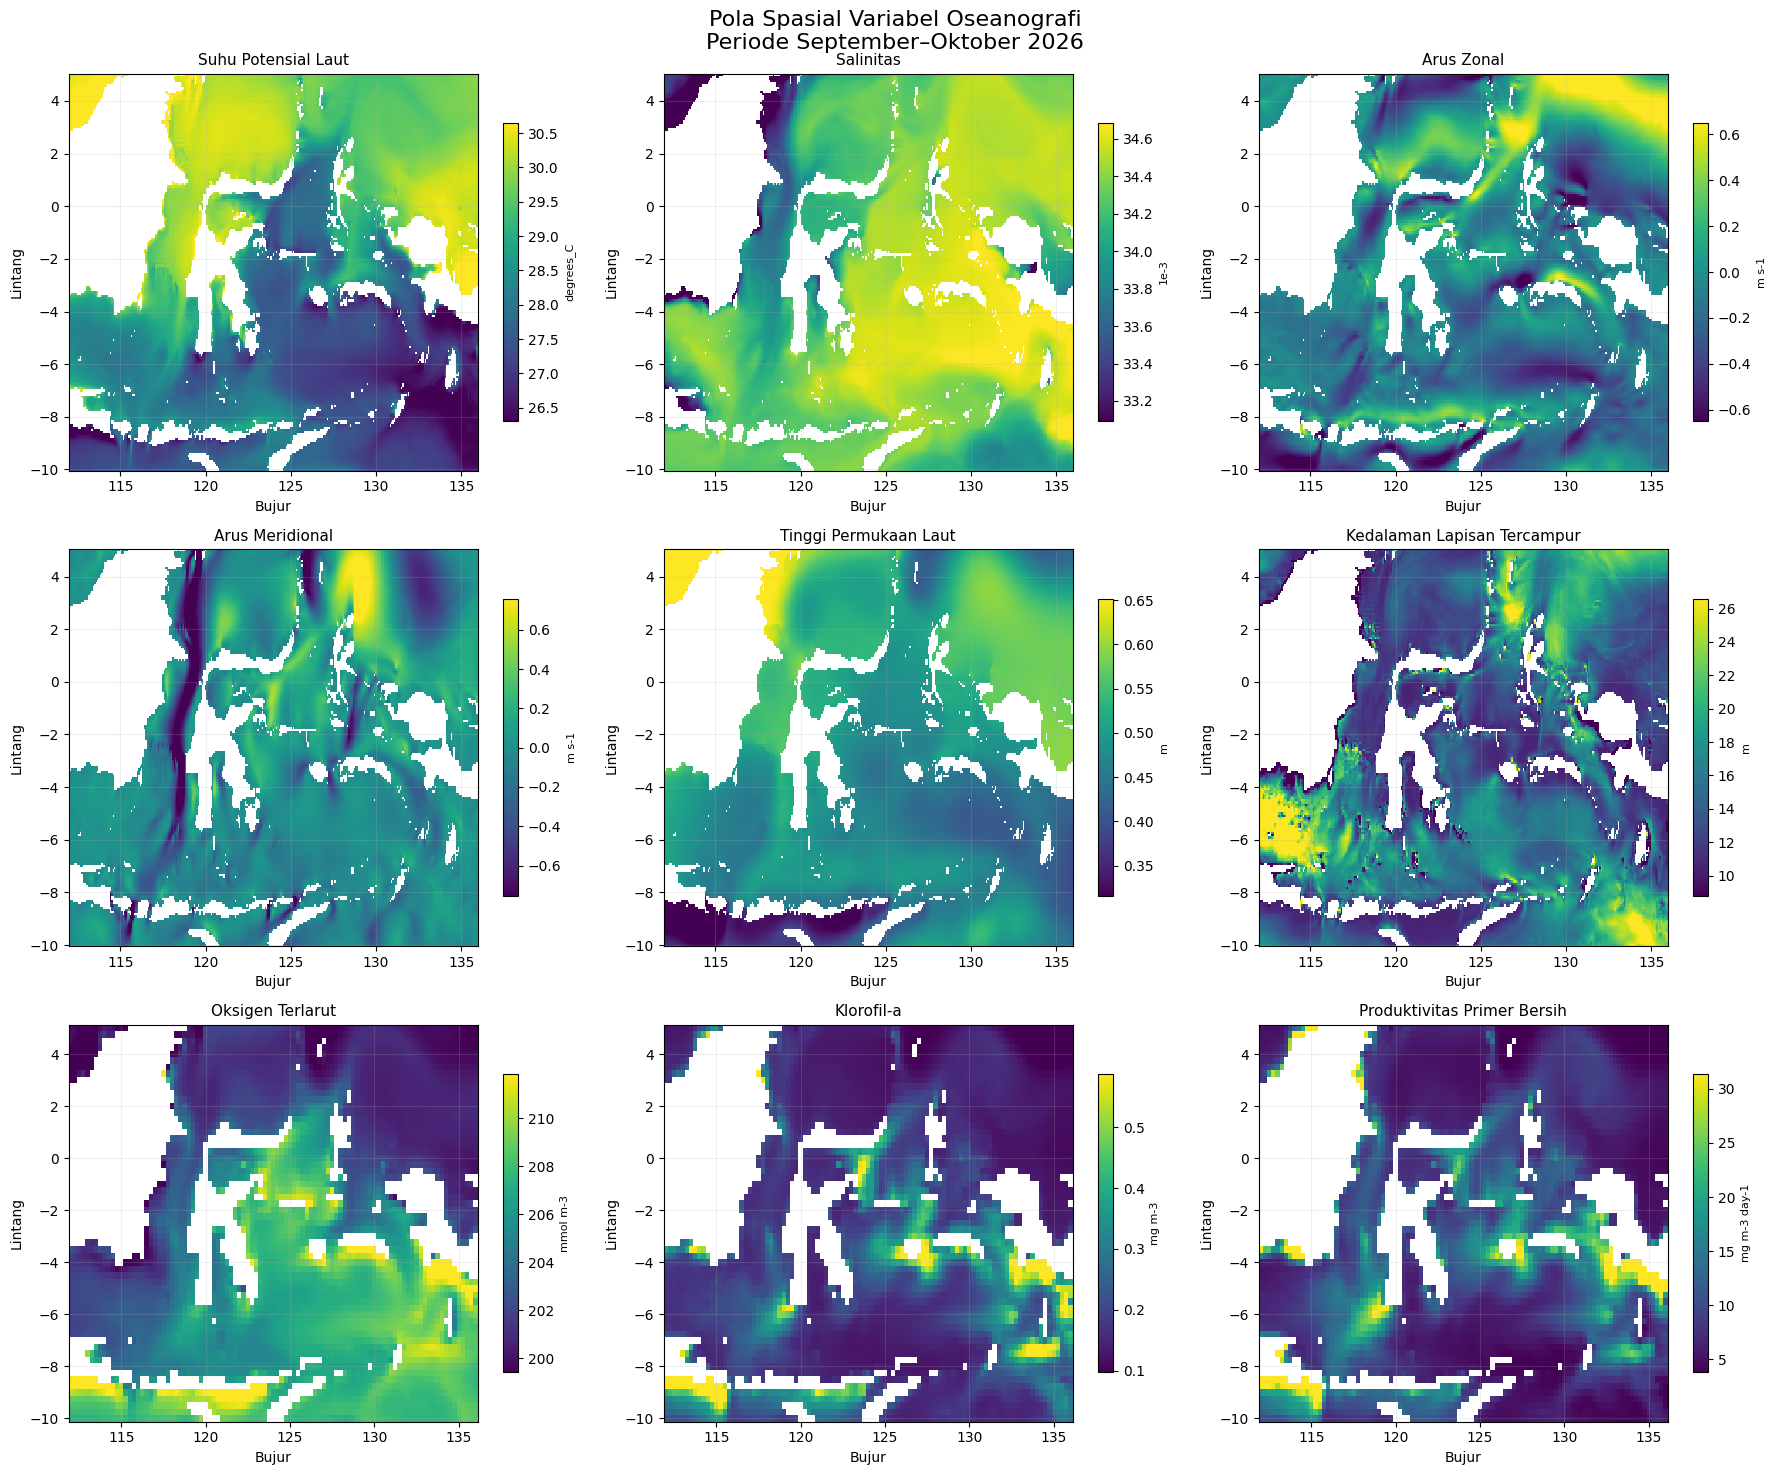

In [12]:

fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.ravel()

nama_variabel = {
    "thetao": "Suhu Potensial Laut",
    "so": "Salinitas",
    "uo": "Arus Zonal",
    "vo": "Arus Meridional",
    "zos": "Tinggi Permukaan Laut",
    "mlotst": "Kedalaman Lapisan Tercampur",
    "o2": "Oksigen Terlarut",
    "chl": "Klorofil-a",
    "nppv": "Produktivitas Primer Bersih"
}

for i, var in enumerate(daftar_variabel):
    ax = axes[i]
    da = data_periode[var]

    p = da.plot(
        ax=ax,
        x="longitude",
        y="latitude",
        cmap="viridis",
        robust=True,
        add_colorbar=False
    )

    cb = fig.colorbar(p, ax=ax, shrink=0.75)
    cb.set_label(da.attrs.get("units", "-"), fontsize=8)

    ax.set_title(nama_variabel[var], fontsize=11)
    ax.set_xlabel("Bujur")
    ax.set_ylabel("Lintang")
    ax.grid(alpha=0.2)

plt.suptitle(
    "Pola Spasial Variabel Oseanografi\n"
    "Periode September–Oktober 2026",
    fontsize=16
)
plt.tight_layout()
plt.show()


In [9]:

tabel_thetao = (
    data_periode["thetao"]
    .to_dataframe(name="thetao")
    .reset_index()
    .dropna(subset=["thetao"])
)

display(tabel_thetao.head(20))
print(tabel_thetao["thetao"].describe())


,latitude,longitude,depth,thetao
0,-10.0,112.000015,0.494025,27.207335
1,-10.0,112.083351,0.494025,27.214911
2,-10.0,112.166679,0.494025,27.221664
3,-10.0,112.250015,0.494025,27.223803
4,-10.0,112.333351,0.494025,27.224140
5,-10.0,112.416679,0.494025,27.224201
6,-10.0,112.500015,0.494025,27.226116
7,-10.0,112.583351,0.494025,27.229101
8,-10.0,112.666687,0.494025,27.232952
9,-10.0,112.750015,0.494025,27.240250


count    40213.000000
mean        28.528740
std          1.298141
min         24.601139
25%         27.410166
50%         28.292236
75%         29.715813
max         32.311768
Name: thetao, dtype: float64


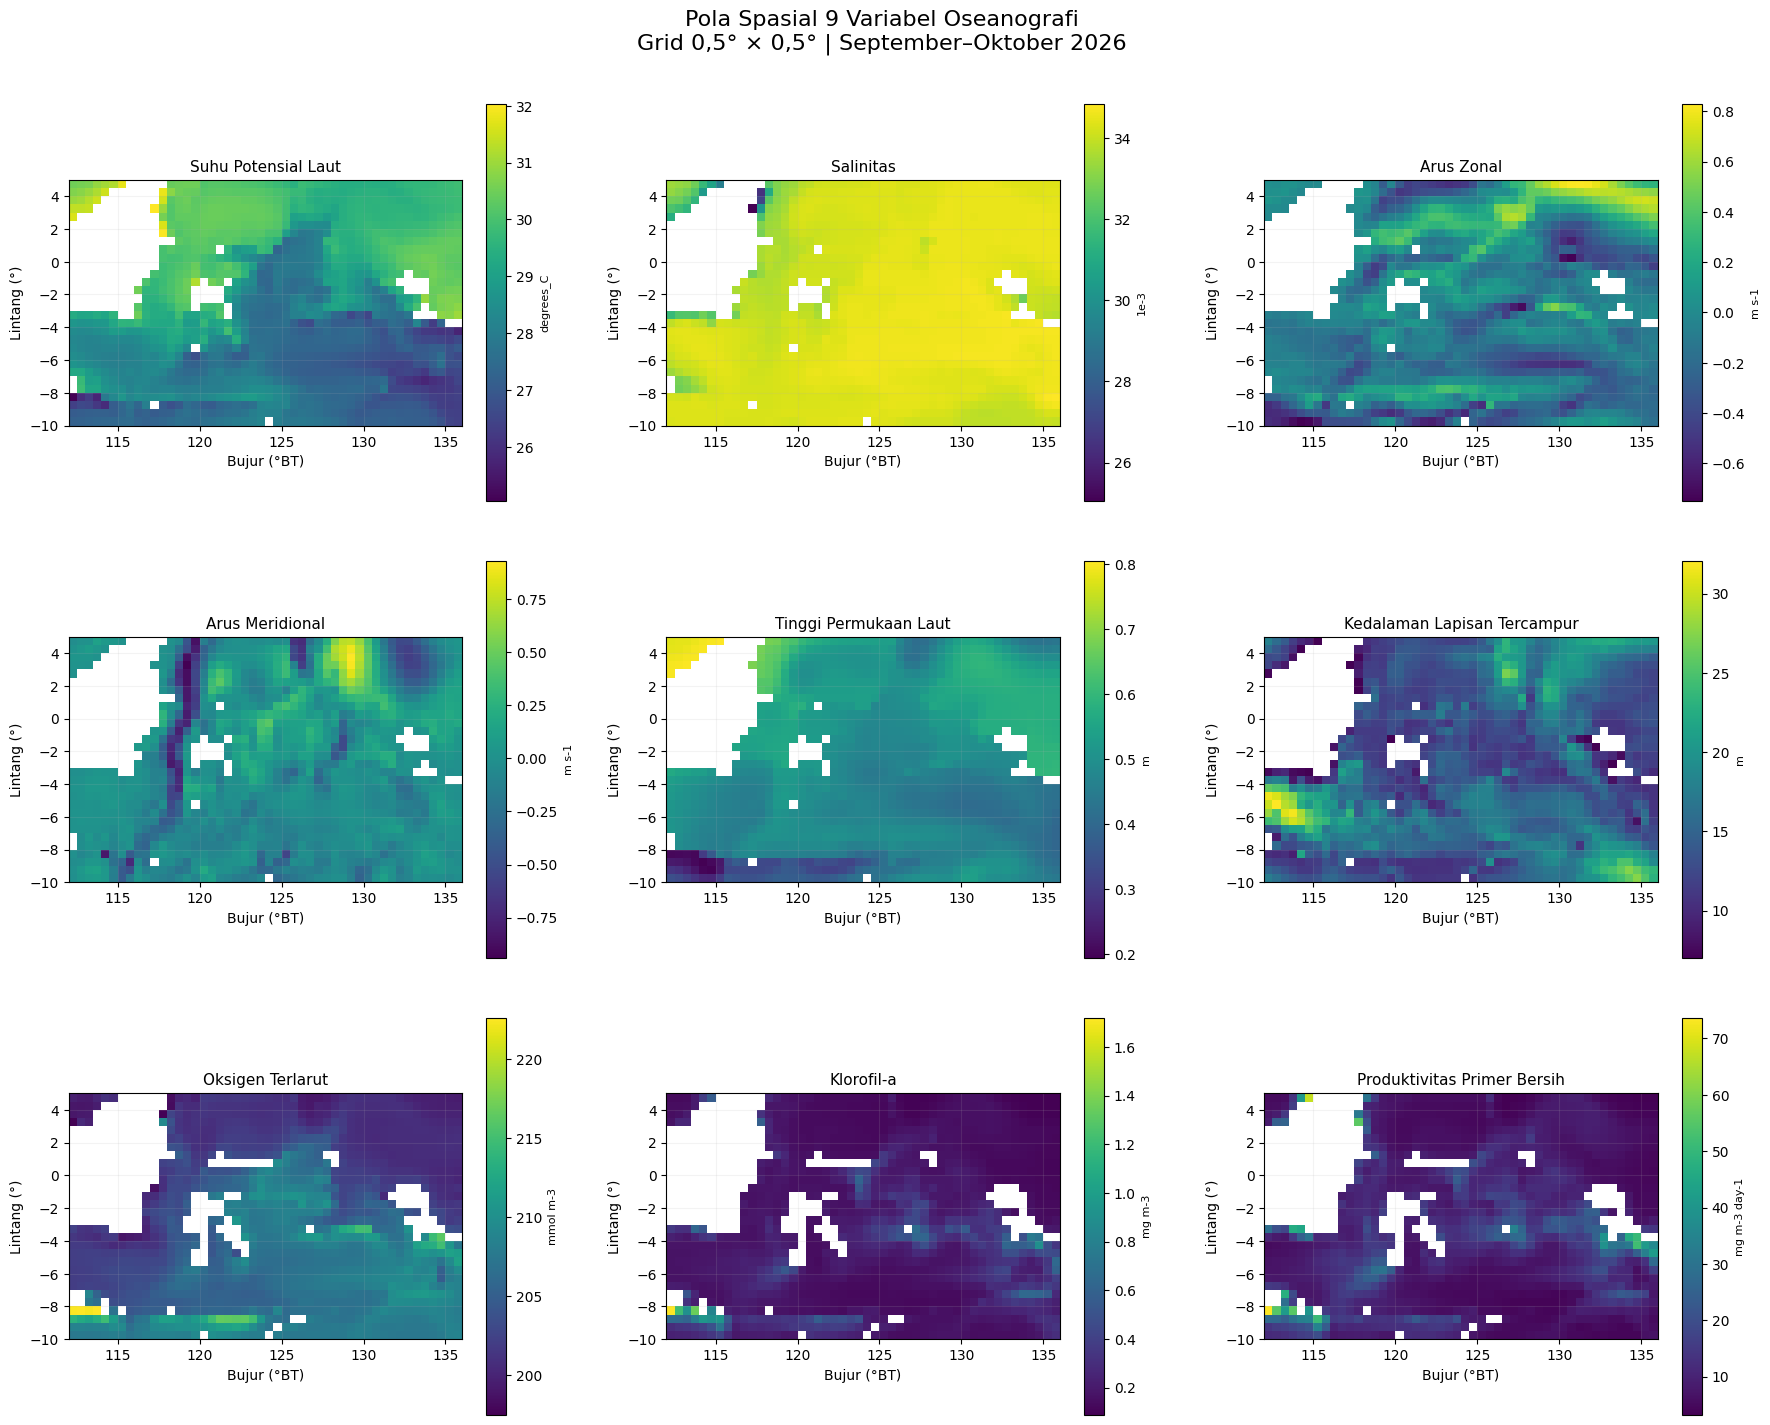

In [14]:

import matplotlib.pyplot as plt

nama_variabel = {
    "thetao": "Suhu Potensial Laut",
    "so": "Salinitas",
    "uo": "Arus Zonal",
    "vo": "Arus Meridional",
    "zos": "Tinggi Permukaan Laut",
    "mlotst": "Kedalaman Lapisan Tercampur",
    "o2": "Oksigen Terlarut",
    "chl": "Klorofil-a",
    "nppv": "Produktivitas Primer Bersih"
}

fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.ravel()

for i, var in enumerate(daftar_variabel):

    ax = axes[i]

    # Ubah tabel kembali menjadi matriks grid
    matriks = hasil.pivot(
        index="latitude",
        columns="longitude",
        values=var
    ).sort_index().sort_index(axis=1)

    nilai = matriks.to_numpy()

    mesh = ax.pcolormesh(
        lon_edges,
        lat_edges,
        nilai,
        cmap="viridis",
        shading="flat"
    )

    cb = fig.colorbar(mesh, ax=ax, shrink=0.8)
    cb.set_label(
        data_nc[var].attrs.get("units", "-"),
        fontsize=8
    )

    ax.set_title(nama_variabel[var], fontsize=11)
    ax.set_xlabel("Bujur (°BT)")
    ax.set_ylabel("Lintang (°)")
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)

plt.suptitle(
    "Pola Spasial 9 Variabel Oseanografi\n"
    "Grid 0,5° × 0,5° | September–Oktober 2026",
    fontsize=16
)

plt.tight_layout()
plt.show()
